# Notebook 09 — Prediction Reliability and Explainability

**Research project:** Customer Segmentation and Retention Analysis Using Machine Learning and Statistical Modelling  
**Scope:** explain the saved Purchase Clock and conditional-spending models; evaluate frozen historical forecasts.  
**Forecast cutoff:** September 10, 2010 · **TEST cohort:** 3,373 customers.

> Historical demonstration only. These forecasts reproduce saved-model outputs at a recorded 2010 cutoff. They are not current-business predictions, recommendations, or guarantees.

## 01. Research objective and introduction

This study explains why the saved models assign their historical 30/60/90-day
purchase and expected-revenue forecasts, measures retrospective calibration,
and summarizes empirical performance for cutoff-valid customer groups. It
preserves the existing fitted models and predictions. TEST outcomes are used
only for retrospective evaluation, never to fit references, select bin edges,
or tune a forecasting method.

## 02. Existing model architecture

The Purchase Clock is the saved `purchase-clock-v2` binary logistic hazard
pipeline. The fitted preprocessing transforms the customer-level historical
features and expands them across nine 10-day interval indicators. The final
model has 21 transformed inputs. Cumulative P30/P60/P90 are reconstructed from
the saved conditional interval hazards, not from an independent horizon model.

The spending bundle is `spending-forecast-v2`: horizon-specific Ridge pipelines
for conditional 30/60/90-day spending. They preserve saved imputation, feature
transformation, clipping, scaling, categorical encoding, log-space target
training, and the fitted smearing correction used for retransformation.

The exact bundle metadata and fitted feature counts below come from the
committed saved artifacts. No model is retrained in this notebook.

## 03. Formal explanation methodology and temporal rules

For interval `t`, the logistic score is `β₀ + Σ βⱼ zⱼ`; its fitted hazard is
`sigmoid(score)`. The additive terms are exact only in transformed log-odds
space. Cumulative purchase probability is nonlinear:

`P(T ≤ H) = 1 − ∏ₜ₌₁ᴴ (1 − hₜ)`.

For cumulative explanation, each individual feature is replaced with a
TRAIN-derived median or deterministic categorical mode, then the complete
hazard curve is recomputed. The signed value is original probability minus
reference-replacement probability. These are model-input sensitivities, not
causal effects; replacing correlated or derived features independently can
produce an unrealistic profile.

All TEST features use only transactions strictly before 2010-09-10. Reference
profiles and numeric 1st/99th percentile support ranges use saved-model TRAIN
rows only. Validation probabilities, available before the forecast cutoff,
select diagnostic calibration bins. TEST outcomes do not select or tune the
method.

In [1]:
import sys
from pathlib import Path

candidate_roots = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    root for root in candidate_roots
    if (root / "src" / "purchase_clock.py").is_file()
    and (root / "models" / "purchase_clock").is_dir()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import purchase_clock as pc
from src import spending_model as sm
from src.explainability import (
    decompose_expected_revenue,
    explain_conditional_spending,
    explain_customer_purchase_clock,
)
from src.prediction_reliability import assess_distribution_support
from src.reliability_research import (
    profile_warm_api_endpoints,
    run_reliability_analysis,
)

analysis = run_reliability_analysis(PROJECT_ROOT)
artifact = analysis["artifact"]
evaluation = artifact["evaluation"]
reference_profile = analysis["reference_profile"]
test_features = analysis["test_features"]
test_predictions = analysis["test_predictions"]
profile = analysis["profiling"]

print("Project root:", PROJECT_ROOT)
print("TEST cutoff:", artifact["metadata"]["forecast_cutoff"])
print("TEST customers:", evaluation["evaluation_customer_count"])
print("Purchase Clock:", artifact["metadata"]["purchase_clock_model_version"])
print("Spending model:", artifact["metadata"]["spending_model_version"])

Project root: /home/runner/workspace/.local/worktrees/notebook09
TEST cutoff: 2010-09-10
TEST customers: 3373
Purchase Clock: purchase-clock-v2
Spending model: spending-forecast-v2


## 04. Conditional hazard decomposition

The case below is selected by lowest eligible customer ID, not by outcome or
forecast quality. Each interval row reports its actual fitted hazard and the
largest absolute transformed logit contributions. The reconstruction is checked
against the saved fitted estimator at `rtol=1e-10`, `atol=1e-12`.

In [2]:
purchase_case = analysis["purchase_case_explanation"]
hazard_rows = []
for interval in purchase_case["interval_decompositions"]:
    largest = interval["feature_contributions"][0]
    hazard_rows.append({
        "interval_days": interval["interval_days"],
        "hazard": interval["predicted_hazard"],
        "reconstructed_hazard": interval["reconstructed_hazard"],
        "logit_intercept": interval["logit_intercept"],
        "largest_logit_feature": largest["model_feature"],
        "largest_logit_contribution": largest["logit_contribution"],
    })
display(pd.DataFrame(hazard_rows).round(6))
print("Exact reconstruction tolerance:", purchase_case["reconstruction_tolerance"])

,interval_days,hazard,reconstructed_hazard,logit_intercept,largest_logit_feature,largest_logit_contribution
0,10,0.121316,0.121316,-1.497162,Frequency,1.611226
1,20,0.096746,0.096746,-1.497162,Frequency,1.611226
2,30,0.125068,0.125068,-1.497162,Frequency,1.611226
3,40,0.080090,0.080090,-1.497162,Frequency,1.611226
4,50,0.073488,0.073488,-1.497162,Frequency,1.611226
5,60,0.128921,0.128921,-1.497162,Frequency,1.611226
6,70,0.059477,0.059477,-1.497162,Frequency,1.611226
7,80,0.105248,0.105248,-1.497162,Frequency,1.611226
8,90,0.081031,0.081031,-1.497162,Frequency,1.611226


Exact reconstruction tolerance: {'rtol': 1e-10, 'atol': 1e-12}


## 05. Cumulative purchase probability explanation

The table compares the original P30/P60/P90 forecast with the combined
TRAIN-derived reference profile. Single-input sensitivities are directional
comparisons against that feature's reference replacement; they are not additive
contributions and do not sum to the total probability.

In [3]:
cumulative_rows = []
for horizon in (30, 60, 90):
    cumulative_rows.append({
        "horizon_days": horizon,
        "saved_model_probability": purchase_case["purchase_probabilities"][str(horizon)],
        "combined_train_reference_probability": purchase_case[
            "reference_profile_probabilities"
        ][str(horizon)],
    })
display(pd.DataFrame(cumulative_rows).style.format({
    "saved_model_probability": "{:.4f}",
    "combined_train_reference_probability": "{:.4f}",
}))
effect_rows = []
for effect in purchase_case["feature_effects"]:
    effect_rows.append({
        "feature": effect["feature"],
        "original_value": effect["original_value"],
        "train_reference": effect["reference_value"],
        "P30_effect": effect["probability_effects"]["30"],
        "P60_effect": effect["probability_effects"]["60"],
        "P90_effect": effect["probability_effects"]["90"],
    })
display(pd.DataFrame(effect_rows).round(5))
print("Direction:", "original probability minus reference-replacement probability")
print("Limitations:", *purchase_case["model_input_limitations"], sep="\n- ")

,horizon_days,saved_model_probability,combined_train_reference_probability
0,30,0.3056,0.1713
1,60,0.4845,0.2888
2,90,0.6013,0.3764


,feature,original_value,train_reference,P30_effect,P60_effect,P90_effect
0,Frequency,11,1.0,0.24493,0.37729,0.45613
1,Tenure_obs_days,269.643056,74.436458,-0.22071,-0.25954,-0.24883
2,SpendRate_per_obs_day,1.382791,9.516569,0.15027,0.22081,0.25575
3,AOV,33.896364,296.104167,-0.20708,-0.24585,-0.23747
4,Median_Gap_days,5.987847,20.954861,-0.08104,-0.10450,-0.10799
5,Hist_Segment,Recent / Active,Lapsed / At-Risk,-0.04939,-0.06493,-0.06821
6,Recency,73,31.0,0.02929,0.04031,0.04406
7,Monetary_Gross,372.86,395.9,-0.00635,-0.00856,-0.00919
8,PurchaseRate_per_obs_day,0.040795,0.031643,0.00222,0.00300,0.00324
9,Recent_Orders,1,1.0,0.00000,0.00000,0.00000


Direction: original probability minus reference-replacement probability
Limitations:
- Feature changes are model-input substitutions, not causal interventions.
- Changing one derived feature at a time can create an unrealistic feature combination.
- Historical features and fitted segment membership are not direct customer controls.


## 06. Conditional spending explanation

Each horizon uses its own saved spending pipeline and TRAIN reference profile.
The log score is reconstructed from the fitted Ridge intercept and transformed
feature contributions. Currency output is the saved pipeline's smearing-adjusted
conditional estimate; individual log-space terms are not additive pound values.

In [4]:
case_features = (
    test_features.sort_values("Customer ID")
    .iloc[[0]]
    .loc[:, list(sm.BASE_FEATURE_COLUMNS)]
    .reset_index(drop=True)
)
spending_rows = []
spending_explanations = {}
for horizon in (30, 60, 90):
    explanation = explain_conditional_spending(
        analysis["spending_bundle"],
        case_features,
        horizon,
        reference_profile["spending"][str(horizon)]["reference_values"],
    )
    spending_explanations[horizon] = explanation
    spending_rows.append({
        "horizon_days": horizon,
        "conditional_expected_spending": explanation["conditional_expected_spending"],
        "log_score": explanation["log_score"],
        "retransformation": explanation["retransformation_method"],
        "largest_log_score_feature": explanation["log_score_contributions"][0][
            "model_feature"
        ],
    })
display(pd.DataFrame(spending_rows).round(4))

,horizon_days,conditional_expected_spending,log_score,retransformation,largest_log_score_feature
0,30,106.7218,4.4108,expm1-scale conditional mean via TRAIN-only 5-...,AOV
1,60,149.5657,4.7657,expm1-scale conditional mean via TRAIN-only 5-...,AOV
2,90,226.9150,5.1351,expm1-scale conditional mean via TRAIN-only 5-...,SpendRate_per_obs_day


## 07. Expected revenue decomposition

The saved forecast is checked as purchase probability multiplied by
conditional expected spending. All three values come from the actual saved
model pipelines for the selected TEST customer; no near-zero division is used.

In [5]:
case_id = int(case_features.iloc[0]["Customer ID"])
saved_case_forecast = test_predictions.loc[
    test_predictions["Customer ID"].eq(case_id)
].iloc[0]
revenue_rows = []
for horizon in (30, 60, 90):
    saved_probability = float(saved_case_forecast[f"personalized_P{horizon}"])
    saved_revenue = float(
        saved_case_forecast[f"personalized_expected_revenue_{horizon}d"]
    )
    decomposition = decompose_expected_revenue(
        saved_probability,
        spending_explanations[horizon]["conditional_expected_spending"],
        saved_revenue,
    )
    revenue_rows.append({
        "horizon_days": horizon,
        "purchase_probability": decomposition["purchase_probability"],
        "conditional_expected_spending": decomposition[
            "conditional_expected_spending"
        ],
        "saved_expected_revenue": decomposition["personalized_expected_revenue"],
        "reconstructed_expected_revenue": decomposition[
            "reconstructed_expected_revenue"
        ],
    })
display(pd.DataFrame(revenue_rows).round(4))

,horizon_days,purchase_probability,conditional_expected_spending,saved_expected_revenue,reconstructed_expected_revenue
0,30,0.3056,106.7218,32.6130,32.6130
1,60,0.4845,149.5657,72.4572,72.4572
2,90,0.6013,226.9150,136.4446,136.4446


## 08. Calibration analysis

Calibration is evaluated retrospectively on the fixed TEST cohort after edges
were frozen from eligible validation probabilities. ECE is the bin-count-weighted
absolute gap; MCE is the largest populated-bin gap. Neither is a universal
reliability score.

,horizon_days,customer_count,mean_predicted_probability,observed_purchase_rate,signed_calibration_gap,brier_score,log_loss,roc_auc,average_precision,expected_calibration_error,maximum_calibration_error
0,30,3373,0.3315,0.2793,0.0522,0.1785,0.5403,0.7209,0.5376,0.0606,0.1689
1,60,3373,0.4779,0.4714,0.0065,0.2142,0.6226,0.7218,0.7163,0.0623,0.1290
2,90,3373,0.5654,0.5734,-0.0080,0.2153,0.6282,0.7194,0.7847,0.0689,0.2545


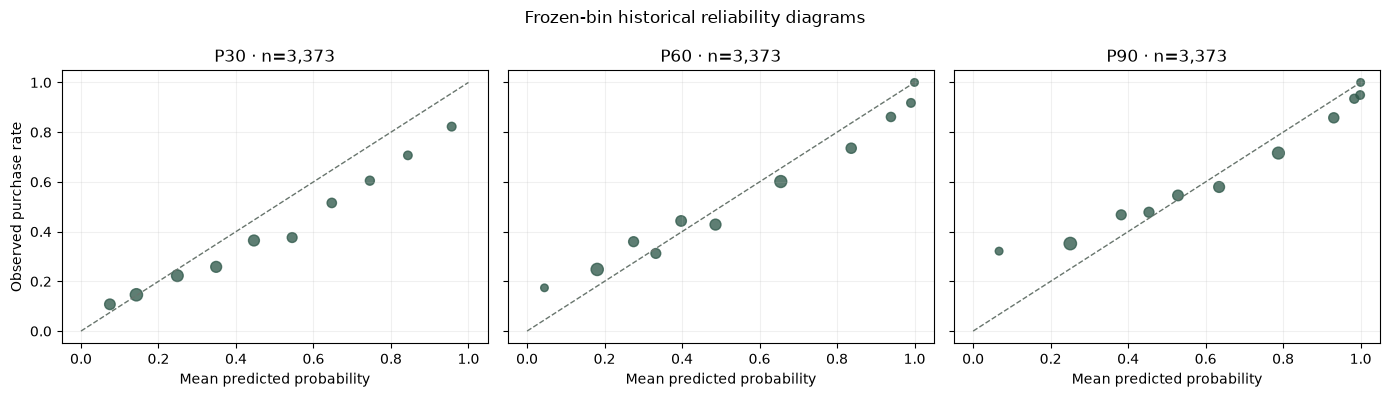

In [6]:
calibration_table = pd.DataFrame(evaluation["purchase_calibration"])[[
    "horizon_days", "customer_count", "mean_predicted_probability",
    "observed_purchase_rate", "signed_calibration_gap", "brier_score",
    "log_loss", "roc_auc", "average_precision",
    "expected_calibration_error", "maximum_calibration_error",
]]
display(calibration_table.round(4))

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True, sharey=True)
for axis, result in zip(axes, evaluation["purchase_calibration"], strict=True):
    bins = pd.DataFrame(result["calibration_bins"])
    populated = bins.loc[bins["customer_count"].gt(0)]
    axis.plot([0, 1], [0, 1], color="#68756d", linestyle="--", linewidth=1)
    points = axis.scatter(
        populated["mean_predicted_probability"],
        populated["observed_purchase_rate"],
        s=20 + np.sqrt(populated["customer_count"]) * 2,
        c="#315a4c",
        alpha=0.78,
    )
    axis.set_title(f'P{result["horizon_days"]} · n={result["customer_count"]:,}')
    axis.set_xlabel("Mean predicted probability")
    axis.grid(alpha=0.18)
axes[0].set_ylabel("Observed purchase rate")
fig.suptitle("Frozen-bin historical reliability diagrams")
fig.tight_layout()
plt.show()

## 09. Calibration bin sensitivity

Edges are selected from validation predictions using a minimum support of 30
per populated bin, then maximum minimum-bin support and fewer empty bins.
Sensitivity compares the frozen selection with equal-width bins; the TEST
comparison is diagnostic only and does not change the selected policy.

In [7]:
bin_sensitivity = pd.DataFrame(evaluation["calibration_bin_sensitivity"])
display(bin_sensitivity)
selection_rows = []
for horizon, selection in artifact["validation"]["bin_selection_by_horizon"].items():
    chosen = selection["binning"]["selected_candidate"]
    selection_rows.append({
        "horizon_days": int(horizon),
        "validation_cutoff": selection["validation_cutoff"],
        "validation_customers": selection["validation_customer_count"],
        "selected_method": selection["binning"]["selected_method"],
        "minimum_populated_bin_support": chosen["minimum_populated_bin_support"],
        "empty_bins": chosen["empty_bins"],
        "minimum_required_support": selection["binning"][
            "minimum_validation_bin_support"
        ],
    })
display(pd.DataFrame(selection_rows))

,horizon_days,selected_method,selected_ece,selected_mce,equal_width_10_ece,equal_width_10_mce,interpretation
0,30,equal_width_10,0.060562,0.168878,0.060562,0.168878,TEST is used only to compare frozen diagnostic...
1,60,validation_quantile,0.062264,0.129044,0.056694,0.108703,TEST is used only to compare frozen diagnostic...
2,90,validation_quantile,0.068905,0.254505,0.065745,0.251127,TEST is used only to compare frozen diagnostic...


,horizon_days,validation_cutoff,validation_customers,selected_method,minimum_populated_bin_support,empty_bins,minimum_required_support
0,30,2010-08-01,3159,equal_width_10,59,0,30
1,60,2010-07-01,2973,validation_quantile,297,1,30
2,90,2010-07-01,2973,validation_quantile,297,1,30


## 10. Reliability by customer history

History groups are defined from cutoff-time purchase frequency: exactly one,
two to four, and five or more purchases. The 100-customer support threshold was
fixed in the analysis configuration before the TEST results were examined.

,group,customer_count,mean_predicted_probability,observed_purchase_rate,brier_score,average_precision,calibration_gap,status
0,Exactly one purchase,1281,0.1551,0.1374,0.1192,0.1812,0.0177,well_supported_historical_evaluation_group
3,Five or more purchases,726,0.6403,0.5455,0.2433,0.7129,0.0948,well_supported_historical_evaluation_group
6,Two to four purchases,1366,0.3328,0.2709,0.1997,0.3532,0.0619,well_supported_historical_evaluation_group


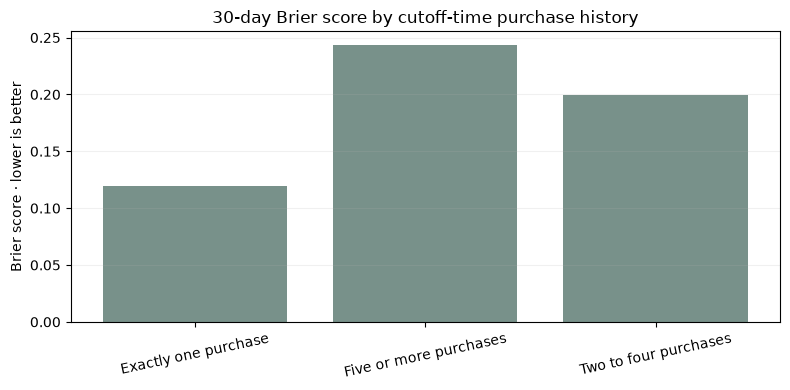

In [8]:
history_results = pd.DataFrame([
    row for row in evaluation["subgroups"]
    if row["group_type"] == "history_group"
])
history_30 = history_results.loc[history_results["horizon_days"].eq(30)].copy()
display(history_30[[
    "group", "customer_count", "mean_predicted_probability",
    "observed_purchase_rate", "brier_score", "average_precision",
    "calibration_gap", "status",
]].sort_values("group").round(4))
fig, axis = plt.subplots(figsize=(8, 4))
ordered = history_30.sort_values("group")
axis.bar(ordered["group"], ordered["brier_score"], color="#78918a")
axis.set_ylabel("Brier score · lower is better")
axis.set_title("30-day Brier score by cutoff-time purchase history")
axis.tick_params(axis="x", rotation=12)
axis.grid(axis="y", alpha=0.18)
fig.tight_layout()
plt.show()

## 11. Reliability by historical forecast-time segment

These are the saved forecast-time segment labels, not full-period
retrospective descriptive clusters. Segment metrics are historical subgroup
evidence and do not imply causal effects or future guarantees.

,group,customer_count,mean_predicted_probability,observed_purchase_rate,brier_score,average_precision,calibration_gap,status
0,Lapsed / At-Risk,2088,0.2009,0.1743,0.1434,0.2439,0.0266,well_supported_historical_evaluation_group
3,Recent / Active,1285,0.5437,0.4498,0.2356,0.6461,0.0939,well_supported_historical_evaluation_group


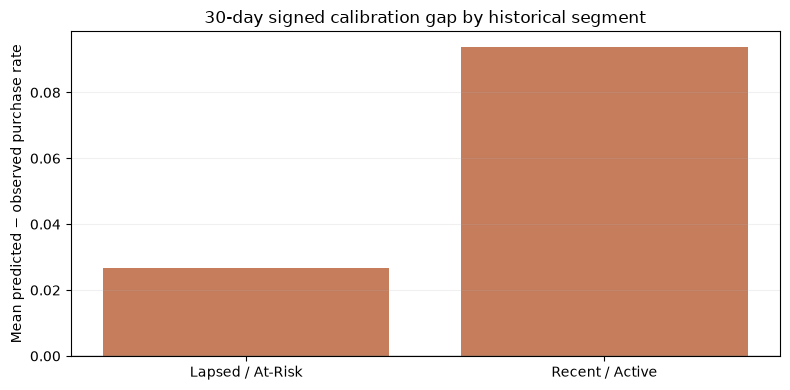

In [9]:
segment_results = pd.DataFrame([
    row for row in evaluation["subgroups"]
    if row["group_type"] == "Hist_Segment"
])
segment_30 = segment_results.loc[segment_results["horizon_days"].eq(30)].copy()
display(segment_30[[
    "group", "customer_count", "mean_predicted_probability",
    "observed_purchase_rate", "brier_score", "average_precision",
    "calibration_gap", "status",
]].sort_values("group").round(4))
fig, axis = plt.subplots(figsize=(8, 4))
ordered = segment_30.sort_values("group")
axis.bar(ordered["group"], ordered["calibration_gap"], color="#c57d5c")
axis.axhline(0, color="#68756d", linewidth=1)
axis.set_ylabel("Mean predicted − observed purchase rate")
axis.set_title("30-day signed calibration gap by historical segment")
axis.grid(axis="y", alpha=0.18)
fig.tight_layout()
plt.show()

## 12. Customer-level bootstrap confidence intervals

The fixed-model percentile bootstrap resamples complete customer observations
with replacement within each cutoff, horizon, and group. It quantifies
empirical group-metric uncertainty, not model-parameter uncertainty or an
individual customer's outcome probability.

In [10]:
bootstrap = pd.DataFrame(evaluation["bootstrap_intervals"])
history_bootstrap = bootstrap.loc[
    bootstrap["group_type"].eq("history_group")
    & bootstrap["horizon_days"].eq(30)
    & bootstrap["metric"].isin([
        "observed_purchase_rate", "calibration_gap", "brier_score"
    ])
]
display(history_bootstrap[[
    "group", "metric", "customer_count", "lower", "upper",
    "successful_bootstrap_samples", "status",
]].sort_values(["group", "metric"]).round(5))
revenue_intervals = bootstrap.loc[
    bootstrap["group_type"].eq("history_group")
    & bootstrap["horizon_days"].eq(30)
    & bootstrap["metric"].eq("mean_forecast_bias")
    & bootstrap["revenue_model"].eq("Personalized two-stage")
]
display(revenue_intervals[[
    "group", "revenue_model", "customer_count", "lower", "upper",
    "successful_bootstrap_samples", "status",
]].sort_values("group").round(3))

,group,metric,customer_count,lower,upper,successful_bootstrap_samples,status
27,Exactly one purchase,brier_score,1281,0.10560,0.13232,500,estimated
18,Exactly one purchase,calibration_gap,1281,-0.00003,0.03531,500,estimated
9,Exactly one purchase,observed_purchase_rate,1281,0.11903,0.15613,500,estimated
28,Five or more purchases,brier_score,726,0.22970,0.25870,500,estimated
19,Five or more purchases,calibration_gap,726,0.05778,0.12839,500,estimated
10,Five or more purchases,observed_purchase_rate,726,0.51030,0.58127,500,estimated
29,Two to four purchases,brier_score,1366,0.19073,0.20931,500,estimated
20,Two to four purchases,calibration_gap,1366,0.03656,0.08578,500,estimated
11,Two to four purchases,observed_purchase_rate,1366,0.24817,0.29649,500,estimated


,group,revenue_model,customer_count,lower,upper,successful_bootstrap_samples,status
300,Exactly one purchase,Personalized two-stage,1281,-7.451,17.855,500,estimated
301,Five or more purchases,Personalized two-stage,726,-317.315,-50.101,500,estimated
302,Two to four purchases,Personalized two-stage,1366,-4.454,28.564,500,estimated


## 13. Feature-distribution support

Numeric support flags use the TRAIN-only 1st/99th percentile bounds; categorical
flags compare observed labels with the TRAIN category set. These indicate
whether a feature value is outside the chosen historical support range. They
are not probabilities of model failure.

In [11]:
purchase_bundle = analysis["purchase_bundle"]
support_customer = case_features.iloc[0].to_dict()
purchase_inputs = pc._apply_bundle_segmentation(
    purchase_bundle, case_features
).iloc[0].to_dict()
purchase_support = assess_distribution_support(
    purchase_inputs, reference_profile["purchase_clock"]
)
support_rows = [{"model_scope": "purchase_clock", **flag}
                for flag in purchase_support["flags"]]
for horizon in (30, 60, 90):
    spending_inputs = sm.apply_spending_segmentation(
        analysis["spending_bundle"], case_features, horizon
    ).iloc[0].to_dict()
    assessed = assess_distribution_support(
        spending_inputs, reference_profile["spending"][str(horizon)]
    )
    support_rows.extend(
        {"model_scope": f"spending_{horizon}d", **flag}
        for flag in assessed["flags"]
    )
display(pd.DataFrame(support_rows))
print(purchase_support["interpretation"])

,model_scope,feature,value,status,bound
0,purchase_clock,Tenure_obs_days,269.643056,above_train_range,89.546687
1,spending_30d,Tenure_obs_days,269.643056,above_train_range,181.506167
2,spending_60d,Tenure_obs_days,269.643056,above_train_range,150.510083
3,spending_90d,Tenure_obs_days,269.643056,above_train_range,89.546687


Distribution-support flags describe distance from TRAIN reference ranges; they are not probabilities of model failure.


## 14. Spending forecast reliability

MAE, RMSE, mean bias, and portfolio totals follow Notebook 07's original TEST
definition. Error distributions are shown without MAPE because actual zero
revenue makes that percentage undefined. Large-spender sensitivity is explicitly
retrospective and did not select the forecast or thresholds.

,horizon_days,model,n_customers,mae,rmse,mean_forecast_bias,total_predicted_revenue,total_actual_revenue,total_revenue_bias
0,30,Historical spending-rate,3373,296.35,945.39,34.91,858475.87,740721.59,117754.28
1,30,Segment-aware two-stage,3373,284.04,1012.54,3.56,752723.56,740721.59,12001.97
2,30,Personalized two-stage,3373,243.18,871.30,-29.96,639659.40,740721.59,-101062.20
3,60,Historical spending-rate,3373,496.24,1707.90,57.75,1763483.07,1568678.51,194804.56
4,60,Segment-aware two-stage,3373,496.67,1870.18,-32.69,1458412.19,1568678.51,-110266.32
5,60,Personalized two-stage,3373,383.78,1466.12,-92.37,1257116.38,1568678.51,-311562.13
6,90,Historical spending-rate,3373,752.39,2487.43,132.53,2942543.56,2495526.20,447017.36
7,90,Segment-aware two-stage,3373,836.26,2881.40,97.26,2823576.74,2495526.20,328050.54
8,90,Personalized two-stage,3373,547.38,2111.73,-187.86,1861869.51,2495526.20,-633656.69


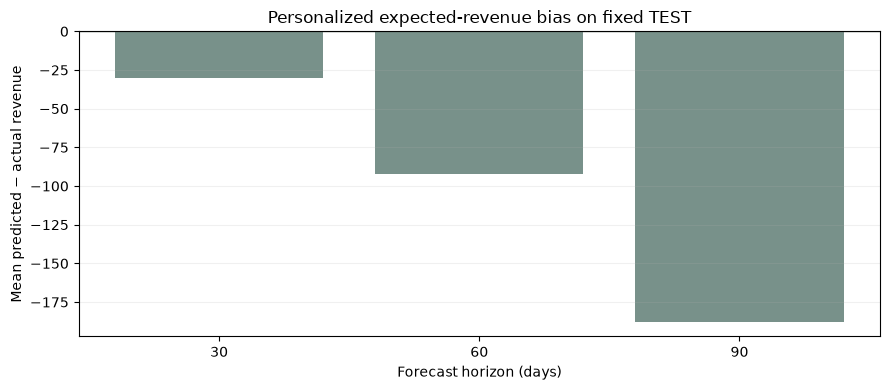

,horizon_days,model,large_spender_count,actual_revenue_threshold,interpretation
0,30,Historical spending-rate,34,2574.5472,Retrospective error sensitivity only; this TES...
1,30,Segment-aware two-stage,34,2574.5472,Retrospective error sensitivity only; this TES...
2,30,Personalized two-stage,34,2574.5472,Retrospective error sensitivity only; this TES...
3,60,Historical spending-rate,34,5162.4896,Retrospective error sensitivity only; this TES...
4,60,Segment-aware two-stage,34,5162.4896,Retrospective error sensitivity only; this TES...
5,60,Personalized two-stage,34,5162.4896,Retrospective error sensitivity only; this TES...
6,90,Historical spending-rate,34,7821.5568,Retrospective error sensitivity only; this TES...
7,90,Segment-aware two-stage,34,7821.5568,Retrospective error sensitivity only; this TES...
8,90,Personalized two-stage,34,7821.5568,Retrospective error sensitivity only; this TES...


In [12]:
revenue_metrics = pd.DataFrame(evaluation["revenue"])
display(revenue_metrics[[
    "horizon_days", "model", "n_customers", "mae", "rmse",
    "mean_forecast_bias", "total_predicted_revenue",
    "total_actual_revenue", "total_revenue_bias",
]].round(2))
fig, axis = plt.subplots(figsize=(9, 4))
personalized = revenue_metrics.loc[
    revenue_metrics["model"].eq("Personalized two-stage")
]
axis.bar(
    personalized["horizon_days"].astype(str),
    personalized["mean_forecast_bias"],
    color="#78918a",
)
axis.axhline(0, color="#68756d", linewidth=1)
axis.set_xlabel("Forecast horizon (days)")
axis.set_ylabel("Mean predicted − actual revenue")
axis.set_title("Personalized expected-revenue bias on fixed TEST")
axis.grid(axis="y", alpha=0.18)
fig.tight_layout()
plt.show()
display(pd.DataFrame(evaluation["large_spender_sensitivity"])[[
    "horizon_days", "model", "large_spender_count",
    "actual_revenue_threshold", "interpretation",
]])

## 15. Representative customer case studies

For each available purchase-history group, the selected profile is the
lowest customer ID in the eligible TEST feature cohort. Selection uses only
history-group membership and ID, not future outcomes, calibration error, or
forecast quality. Customer rows below show saved predictions and feature
support flags, never TEST outcome labels.

In [13]:
case_source = test_features[["Customer ID", "Frequency", "Recency"]].copy()
case_source["history_group"] = np.select(
    [
        case_source["Frequency"].eq(1),
        case_source["Frequency"].between(2, 4),
        case_source["Frequency"].ge(5),
    ],
    [
        "Exactly one purchase",
        "Two to four purchases",
        "Five or more purchases",
    ],
    default="Unknown history",
)
case_summary_rows = []
case_effect_tables = {}
for group_name in [
    "Exactly one purchase",
    "Two to four purchases",
    "Five or more purchases",
]:
    available = case_source.loc[case_source["history_group"].eq(group_name)]
    if available.empty:
        continue
    chosen_id = int(available.sort_values("Customer ID").iloc[0]["Customer ID"])
    chosen_features = (
        test_features.loc[test_features["Customer ID"].eq(chosen_id)]
        .iloc[[0]]
        .loc[:, list(sm.BASE_FEATURE_COLUMNS)]
        .reset_index(drop=True)
    )
    forecast = test_predictions.loc[
        test_predictions["Customer ID"].eq(chosen_id)
    ].iloc[0]
    explanation = explain_customer_purchase_clock(
        purchase_bundle,
        chosen_features,
        reference_profile["purchase_clock"]["reference_values"],
    )
    flags = assess_distribution_support(
        pc._apply_bundle_segmentation(purchase_bundle, chosen_features)
        .iloc[0]
        .to_dict(),
        reference_profile["purchase_clock"],
    )
    case_summary_rows.append({
        "customer_id": chosen_id,
        "history_group": group_name,
        "frequency": int(available.iloc[0]["Frequency"]),
        "recency_days": float(available.iloc[0]["Recency"]),
        "P30": float(forecast["personalized_P30"]),
        "P60": float(forecast["personalized_P60"]),
        "P90": float(forecast["personalized_P90"]),
        "expected_revenue_30d": float(
            forecast["personalized_expected_revenue_30d"]
        ),
        "expected_revenue_60d": float(
            forecast["personalized_expected_revenue_60d"]
        ),
        "expected_revenue_90d": float(
            forecast["personalized_expected_revenue_90d"]
        ),
        "atypical_purchase_inputs": flags["atypical_feature_count"],
        "cutoff": artifact["metadata"]["forecast_cutoff"],
    })
    case_effect_tables[group_name] = pd.DataFrame([
        {
            "feature": effect["feature"],
            "reference_value": effect["reference_value"],
            "P30_sensitivity": effect["probability_effects"]["30"],
            "P60_sensitivity": effect["probability_effects"]["60"],
            "P90_sensitivity": effect["probability_effects"]["90"],
        }
        for effect in explanation["feature_effects"][:5]
    ])
case_studies = pd.DataFrame(case_summary_rows)
display(case_studies.round(4))
for group_name, effects in case_effect_tables.items():
    print(group_name, "· largest absolute single-input sensitivities")
    display(effects.round(5))

,customer_id,history_group,frequency,recency_days,P30,P60,P90,expected_revenue_30d,expected_revenue_60d,expected_revenue_90d,atypical_purchase_inputs,cutoff
0,12355,Exactly one purchase,1,111.0,0.1591,0.2696,0.3529,88.2661,171.0401,185.6010,4,2010-09-10
1,12349,Two to four purchases,2,114.0,0.2185,0.3606,0.4621,145.8080,308.2339,295.5751,3,2010-09-10
2,12346,Five or more purchases,11,73.0,0.3056,0.4845,0.6013,32.6130,72.4572,136.4446,1,2010-09-10


Exactly one purchase · largest absolute single-input sensitivities


,feature,reference_value,P30_sensitivity,P60_sensitivity,P90_sensitivity
0,Recent_Orders,1.00000,-0.12897,-0.19087,-0.22235
1,SpendRate_per_obs_day,9.51657,0.04462,0.07187,0.08996
2,Tenure_obs_days,74.43646,-0.03813,-0.05907,-0.07149
3,Recency,31.00000,0.02501,0.03992,0.04958
4,AOV,296.10417,0.02281,0.03638,0.04514


Two to four purchases · largest absolute single-input sensitivities


,feature,reference_value,P30_sensitivity,P60_sensitivity,P90_sensitivity
0,Recent_Orders,1.00000,-0.16143,-0.22005,-0.23898
1,Monetary_Gross,395.90000,0.07932,0.12278,0.14857
2,Frequency,1.00000,0.06571,0.10104,0.12156
3,Tenure_obs_days,74.43646,-0.07364,-0.10543,-0.11926
4,AOV,296.10417,0.04430,0.06741,0.08035


Five or more purchases · largest absolute single-input sensitivities


,feature,reference_value,P30_sensitivity,P60_sensitivity,P90_sensitivity
0,Frequency,1.00000,0.24493,0.37729,0.45613
1,Tenure_obs_days,74.43646,-0.22071,-0.25954,-0.24883
2,SpendRate_per_obs_day,9.51657,0.15027,0.22081,0.25575
3,AOV,296.10417,-0.20708,-0.24585,-0.23747
4,Median_Gap_days,20.95486,-0.08104,-0.10450,-0.10799


## 16. Limitations and interpretation

- The TEST cohort is a historical evaluation, not a live or current forecast.
- The final 90-day spending model has no eligible prospective validation
  vintage; its TEST revenue results are retrospective.
- ECE/MCE depend on the frozen bins, and some individual bins remain small.
- Bootstrap intervals quantify empirical fixed-model group metrics, not
  parameter or individual-outcome uncertainty.
- A reference profile and single-feature substitution can be unrealistic for
  correlated or derived inputs. They are not causal interventions.
- A TRAIN-range flag is a support diagnostic, not a probability of failure.
- High-spending customers can dominate portfolio errors; the TEST-defined
  99th-percentile sensitivity is retrospective only.
- No calibrator was fitted, no saved model was changed, and no unsupported
  customer reliability percentage is reported.

Aleatoric uncertainty is the remaining randomness in a future purchase;
epistemic uncertainty concerns finite-data model estimation; empirical
calibration uncertainty concerns finite evaluation groups. Only the last is
quantified here, using customer-level resampling.

## 17. Final research findings and artifact export

The saved 30/60/90-day purchase probabilities preserve the original model
outputs and ordering. This analysis adds exact transformed-space hazard
decomposition, TRAIN-reference probability sensitivity, horizon-specific
conditional-spending explanations, frozen-bin reliability diagrams, subgroup
metrics, and customer-level bootstrap intervals. Reliability remains a set of
diagnostics and evidence limitations, not a scalar customer score.

The final cell records warm endpoint latency after one in-process warm-up
request, then lists the versioned outputs written by the reusable `src/`
research code.

In [14]:
warm_api = profile_warm_api_endpoints(PROJECT_ROOT, repetitions=5)
warm_rows = [
    {
        "endpoint": name,
        "median_ms": values["median_ms"],
        "p95_ms": values["p95_ms"],
        "successful_repetitions": values["successful_repetitions"],
        "measurement": values["measurement"],
    }
    for name, values in warm_api["endpoints"].items()
]
display(pd.DataFrame(warm_rows).round(2))

artifact_paths = [
    "data/metrics/prediction_reliability_evaluation.json",
    "data/metrics/prediction_reliability_profiling.json",
    "models/prediction_reliability/metadata.json",
    "models/prediction_reliability/reference_profile.json",
]
print("Artifacts written:")
for path in artifact_paths:
    print("-", path)
print("Profiling environment:", profile["environment"])
print("Measured warm API endpoints:", warm_api["status"])

/home/runner/workspace/.cache/uv/archive-v0/HieiRqobAu6dE-rf/lib/python3.11/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


,endpoint,median_ms,p95_ms,successful_repetitions,measurement
0,summary,17.45,19.00,5,in-process FastAPI TestClient after one warm-u...
1,calibration,17.93,19.55,5,in-process FastAPI TestClient after one warm-u...
2,subgroups,18.20,24.50,5,in-process FastAPI TestClient after one warm-u...
3,revenue,17.85,18.86,5,in-process FastAPI TestClient after one warm-u...
4,explanation,83.43,87.05,5,in-process FastAPI TestClient after one warm-u...
5,customer_reliability,30.70,31.26,5,in-process FastAPI TestClient after one warm-u...


Artifacts written:
- data/metrics/prediction_reliability_evaluation.json
- data/metrics/prediction_reliability_profiling.json
- models/prediction_reliability/metadata.json
- models/prediction_reliability/reference_profile.json
Profiling environment: {'python': '3.11.17', 'pandas': '3.1.1', 'numpy': '2.4.6'}
Measured warm API endpoints: measured
